# 01 — Data Understanding and Exploratory Data Analysis

## Objective
This notebook explores the September 2026 snapshot of Milan Airbnb listings to understand the advertised nightly price, compare accommodation types, inspect missing values, and identify candidate predictors for Model 1.

The exploratory analysis begins with the **full dataset**. Some later comparisons use only listings classified as `Entire home/apt` or `Private room`, without yet applying the final price restrictions. The modeling sample is defined separately in `02_data_preparation.ipynb` using these two room types and **positive numeric prices no greater than 1,000**.

Prices appear with a `$` symbol in the source data. The underlying currency has not been independently verified, so values are reported in the dataset's price units rather than assumed to be euros.

## 1. Load the raw data
The raw compressed CSV is expected at `data/raw/listings.csv.gz`, relative to the repository root.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cwd = Path.cwd().resolve()
if (cwd / "data" / "raw" / "listings.csv.gz").exists():
    project_root = cwd
elif (cwd.parent / "data" / "raw" / "listings.csv.gz").exists():
    project_root = cwd.parent
else:
    raise FileNotFoundError("Expected data/raw/listings.csv.gz in the project root.")

data_path = project_root / "data" / "raw" / "listings.csv.gz"
df = pd.read_csv(data_path, low_memory=False)
print("Dataset shape:", df.shape)


Dataset shape: (25338, 90)


## 2. Parse and inspect the target
Prices are stored as strings with a currency symbol and sometimes thousands separators. Conversion to numeric values is required before calculating descriptive statistics.

In [2]:
df["price_numeric"] = pd.to_numeric(
    df["price"].astype("string")
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False),
    errors="coerce"
)
print("Listings with a numeric price:", df["price_numeric"].notna().sum())
print("Missing numeric prices:", df["price_numeric"].isna().sum())
display(df[["price", "price_numeric"]].head())


Listings with a numeric price: 21654
Missing numeric prices: 3684


,price,price_numeric
0,$203.37,203.37
1,$137.00,137.0
2,NaN,<NA>
3,NaN,<NA>
4,$102.33,102.33


In [4]:
display(df["price_numeric"].describe())

count       21654.0
mean     228.827648
std      824.133616
min            14.1
25%           120.1
50%          163.67
75%           232.0
max         88100.0
Name: price_numeric, dtype: Float64

## 3. Target distribution and extreme prices
The full distribution is highly right-skewed. A second histogram restricted to 0–600 improves readability without changing the dataset.

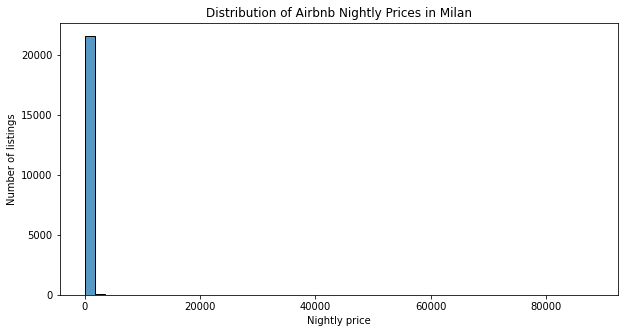

In [5]:
# price histogram

plt.figure(figsize=(10,5))

sns.histplot(data=df, x='price_numeric',bins=50)

plt.title('Distribution of Airbnb Nightly Prices in Milan')
plt.xlabel('Nightly price')
plt.ylabel('Number of listings')

plt.show()


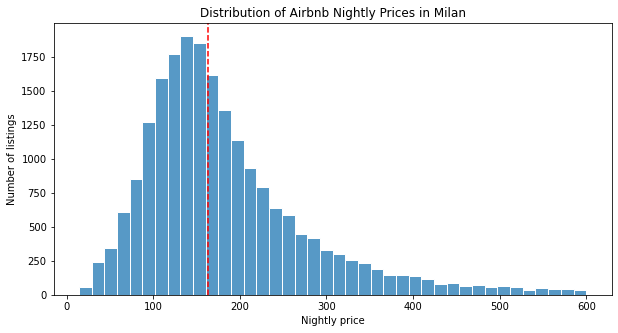

In [6]:
# Closer look price between (0,600)

price_zoom = df.loc[df['price_numeric'].between(0,600),'price_numeric']

plt.figure(figsize=(10,5))

sns.histplot(x=price_zoom,
            bins=40,
            edgecolor='white')


plt.axvline(df['price_numeric'].median(),
           color='red',
           linestyle='--',
           label='Median')

plt.title('Distribution of Airbnb Nightly Prices in Milan')
plt.xlabel('Nightly price')
plt.ylabel('Number of listings')

plt.show()


The upper tail is inspected before defining the target population. Large advertised prices may reflect unusual properties, listing errors, or other factors. However, they are not automatically treated as incorrect.

In [7]:
# Inspect upper-tail price percentiles

percentiles = df['price_numeric'].quantile([0.50,0.75,0.90,0.95,0.99,0.995,0.999])
print(percentiles)

0.500        163.67
0.750         232.0
0.900       347.318
0.950       481.883
0.990        1107.0
0.995    1539.22425
0.999    5636.23171
Name: price_numeric, dtype: Float64


In [8]:
# Inspect the most expensive listings

columns_to_show = [
    "id",
    "name",
    "room_type",
    "accommodates",
    "bedrooms",
    "price_numeric"
]

df.nlargest(10,"price_numeric")[columns_to_show]

,id,name,room_type,accommodates,bedrooms,price_numeric
17725,1462421922032257968,Prestige Penthouse Milano - Corso Como,Entire home/apt,6,2.0,88100.0
15448,1361106000418901132,Cozy Bilocale Duomo Loreto (15' Duomo) WI-FI,Entire home/apt,2,1.0,57765.0
20441,1589078882493761217,Via Torino Heart - trilocale nel cuore di Milano,Entire home/apt,6,2.0,20925.0
16728,1409319205840352630,Penthouse Maison Onice by Maison Senato,Entire home/apt,4,2.0,17633.0
25160,1766148337458343355,Via Torino Heart 2 - trilocale in centro città,Entire home/apt,6,2.0,14400.0
17772,1465789483046374449,Arco 25 | Milano,Entire home/apt,4,1.0,14070.0
18730,1514563677973295242,Suite Vetra • a pochi passi da Duomo,Entire home/apt,4,1.0,13757.0
15922,1379889125392419721,San Siro FB16,Entire home/apt,6,2.0,12889.0
13697,1246948366944313055,Duomo Big House130Mq Vista Tempio+Terrazza Pri...,Entire home/apt,6,2.0,12064.0
12413,1155706241576766107,[Città studi] Prestigioso loft in piazzale gorini,Entire home/apt,4,1.0,11628.0


## 4. Price ceiling sensitivity
The 1,000 ceiling defines the intended market segment. It is not inferred to be a universal outlier threshold.

In [9]:
# Recalculate threshold comparison from the original numeric target

valid_prices = df["price_numeric"].dropna()

thresholds = [400, 600, 1000, 1500, 2000]

results = []

for threshold in thresholds:
    n_kept = (valid_prices <= threshold).sum()
    n_removed = (valid_prices > threshold).sum()

    assert n_kept + n_removed == len(valid_prices)

    results.append({
        "threshold": threshold,
        "listings_kept": n_kept,
        "listings_removed": n_removed,
        "share_kept": round(n_kept / len(valid_prices), 4)
    })

threshold_comparison = pd.DataFrame(results)

print("Total valid prices:", len(valid_prices))
display(threshold_comparison)

Total valid prices: 21654


,threshold,listings_kept,listings_removed,share_kept
0,400,20085,1569,0.9275
1,600,20978,676,0.9688
2,1000,21377,277,0.9872
3,1500,21542,112,0.9948
4,2000,21578,76,0.9965


## 5. Room types and price availability
Missing numeric prices are examined across all room types before narrowing the exploratory sample to `Entire home/apt` and `Private room`.

The resulting `df_selected` includes **all listings in those two categories**, including listings with missing prices or prices above 1,000. It is an exploratory subset, **not the final modeling sample**. The positive-price and upper-price filters are applied in the data preparation notebook.

In [10]:
# Create a temporary indicator for missing numeric prices

df["price_missing"] = df["price_numeric"].isna()

# Analyze missing prices by room type

missing_by_room = (df.groupby("room_type", dropna=False)
    .agg(total_listings = ("price_missing","size"),
         missing_prices = ("price_missing","sum"),
         missing_rate = ("price_missing","mean")
    ).
        sort_values("missing_rate", ascending=False)
                  )

missing_by_room["missing_rate_pct"] = (
    missing_by_room["missing_rate"]*100
)

missing_by_room


,total_listings,missing_prices,missing_rate,missing_rate_pct
room_type,,,,
Hotel room,24,9,0.375000,37.500000
Private room,2948,490,0.166214,16.621438
Shared room,57,9,0.157895,15.789474
Entire home/apt,22309,3176,0.142364,14.236407


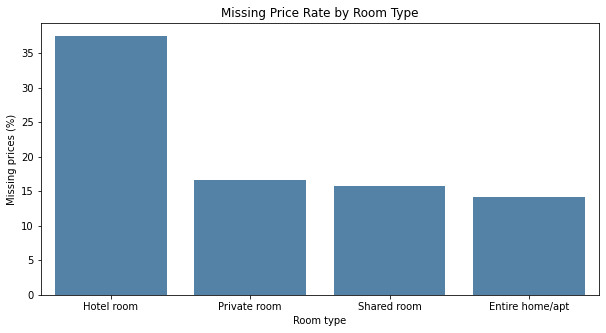

In [11]:
# Plot missing-price percentages by room type

plt.figure(figsize=(10,5))

sns.barplot(
    data = missing_by_room.reset_index(),
    x="room_type",
    y="missing_rate_pct",
    color="steelblue"
)

plt.title("Missing Price Rate by Room Type")
plt.xlabel("Room type")
plt.ylabel("Missing prices (%)")
plt.show()

In [12]:
# Define the room types included in our project

selected_room_types = [
    "Entire home/apt",
    "Private room"
]

df_selected = df.loc[df["room_type"].isin(selected_room_types)].copy()
print("Original listings:", len(df))
print("Selected listings:", len(df_selected))
print("Excluded listings:", len(df)-len(df_selected))

df_selected["room_type"].value_counts()


Original listings: 25338
Selected listings: 25257
Excluded listings: 81


room_type
Entire home/apt    22309
Private room        2948
Name: count, dtype: int64

In [13]:
# Count listings with usable prices by selected room type

price_aviability = (
df_selected.groupby("room_type").agg(
    total_listings=("id","size"),
    valid_prices=("price_numeric","count"),
    median_price=("price_numeric","median")
)
)

price_aviability


,total_listings,valid_prices,median_price
room_type,,,
Entire home/apt,22309,19133,169.0
Private room,2948,2458,106.76


## 6. Prices by accommodation type and guest capacity
The following comparisons use `df_selected`, the exploratory subset containing the two selected room types. Descriptive statistics therefore include all available numeric prices for those room types, whereas the plots use a narrower range to make the distributions easier to read.

The median is reported because extreme prices can strongly influence the mean. These descriptive associations do not establish causality and should not be interpreted as results from the final modeling sample.

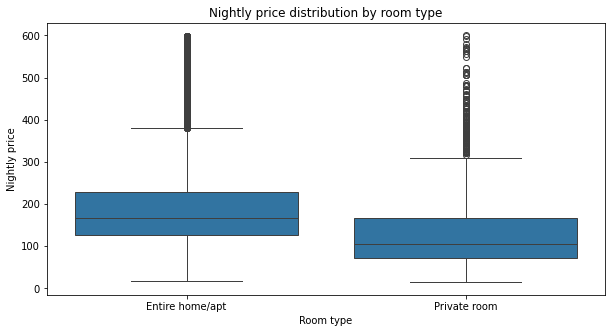

In [40]:
# Compare prices across accommodation types

plot_df = df_selected.loc[df_selected["price_numeric"].between(0,600)].copy()

plt.figure(figsize=(10,5))

sns.boxplot(data = plot_df,
           x="room_type",
           y="price_numeric")

plt.title("Nightly price distribution by room type")
plt.xlabel("Room type")
plt.ylabel("Nightly price")


plt.show()


In [41]:
# Descriptive statistics by accommodation type

price_stats = (
    df_selected.groupby("room_type")["price_numeric"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95])
)

price_stats.round(2)


,count,mean,std,min,25%,50%,75%,90%,95%,max
room_type,,,,,,,,,,
Entire home/apt,19133.0,238.69,869.44,17.59,128.0,169.0,238.67,354.0,496.44,88100.0
Private room,2458.0,155.59,304.34,14.1,73.9,106.76,171.98,257.49,374.88,10797.56


In [42]:
# Explore median price by guest capacity
capacity_stats=(
df_selected.groupby(['room_type','accommodates']).agg(listings = ("price_numeric","count"),
                                                     median_price = ("price_numeric","median")
                                                     ).reset_index()
)

# Show groups with at least 20 priced listings
# Small groups can produce unstable medians.
# The threshold of 20 observations is exploratory.

capacity_stats = capacity_stats.loc[capacity_stats["listings"]>20]

capacity_stats = capacity_stats.sort_values(["room_type","accommodates"])


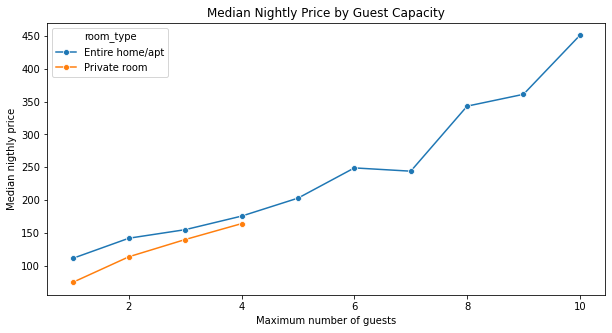

In [43]:
plt.figure(figsize=(10,5))

sns.lineplot(data=capacity_stats,
            x="accommodates",
            y="median_price",
            hue="room_type",
            marker="o")

plt.title("Median Nightly Price by Guest Capacity")
plt.xlabel("Maximum number of guests")
plt.ylabel("Median nigthly price")

plt.show()


## 7. Candidate structural features and missing values
The feature audit includes both potential predictors and variables considered for later extensions. Model 1 uses seven structural inputs: `room_type`, `property_type`, `accommodates`, `bedrooms`, `beds`, `bathrooms_count`, and `bathroom_type`. The two bathroom variables are derived from `bathrooms_text`.

`latitude`, `longitude`, and `amenities` are inspected for availability but **are not used in Model 1**. Location and amenities may be explored in a later model. The original `bathrooms` column is also inspected, but bathroom features for Model 1 are derived from the text field instead.

In [44]:
# Candidate columns to inspect in the dataset

candidate_columns = [
    "room_type",
    "property_type",
    "accommodates",
    "bedrooms",
    "beds",
    "bathrooms",
    "bathrooms_text",
    "latitude",
    "longitude",
    "amenities"
]

feature_audit = pd.DataFrame({
    "feature": candidate_columns,
    "available": [
        col in df.columns
        for col in candidate_columns
    ],
    "missing_pct": [
        round(df[col].isna().mean() * 100, 2)
        if col in df.columns else None
        for col in candidate_columns
    ]
})

feature_audit


,feature,available,missing_pct
0,room_type,True,0.00
1,property_type,True,0.00
2,accommodates,True,0.00
3,bedrooms,True,0.04
4,beds,True,2.19
5,bathrooms,True,100.00
6,bathrooms_text,True,0.02
7,latitude,True,0.00
8,longitude,True,0.00
9,amenities,True,0.00


In [45]:
# Inspect bathroom descriptions

print("Data type:", df_selected["bathrooms_text"].dtype)

print("\nMost common values:")
display(
    df_selected["bathrooms_text"]
    .value_counts(dropna=False)
    .head(20)
)

print("\nMissing values:")
print(df_selected["bathrooms_text"].isna().sum())


Data type: object

Most common values:


bathrooms_text
1 bath               18913
2 baths               2865
1 private bath        1419
1 shared bath          905
1.5 baths              394
3 baths                228
2 shared baths         142
2.5 baths               99
0 baths                 57
4 baths                 49
1.5 shared baths        34
Shared half-bath        32
Half-bath               31
Private half-bath       16
0 shared baths          13
3 shared baths          10
3.5 baths                9
2.5 shared baths         8
5 baths                  8
NaN                      5
Name: count, dtype: int64


Missing values:
5


In [ ]:
# Missing values by room type for structural features

structural_features = [
    "bedrooms",
    "beds",
    "bathrooms_text"
]

missing_structural = (
    df_selected
    .groupby("room_type")[structural_features]
    .agg(lambda x: x.isna().mean() * 100)
    .round(2)
)

missing_structural


## 8. Bathroom descriptions
`bathrooms` is unavailable in this snapshot. The `bathrooms_text` field contains information about bathroom count and whether a bathroom is shared or private.

In [46]:
# Extract numeric bathroom counts from text

bathroom_text = df_selected["bathrooms_text"]

# Extract numbers such as 1, 1.5 or 2
bathroom_numbers = pd.to_numeric(
    bathroom_text.str.extract(r"(\d+(?:\.\d+)?)", expand=False),
    errors="coerce"
)

# Handle descriptions containing "half-bath" without a number
half_bath_mask = (
    bathroom_text.str.contains("half-bath", case=False, na=False)
    & bathroom_numbers.isna()
)

df_selected["bathrooms_count"] = bathroom_numbers.mask(
    half_bath_mask, 0.5
)

# Inspect the conversion
df_selected[
    ["bathrooms_text", "bathrooms_count"]
].drop_duplicates().head(25)


,bathrooms_text,bathrooms_count
0,1 bath,1.0
3,1 private bath,1.0
4,2 baths,2.0
7,1 shared bath,1.0
11,2.5 shared baths,2.5
25,2.5 baths,2.5
58,0 baths,0.0
66,1.5 shared baths,1.5
101,1.5 baths,1.5
112,3.5 baths,3.5


In [47]:
# Check whether bathroom descriptions were converted correctly

print(
    "Missing original bathroom descriptions:",
    df_selected["bathrooms_text"].isna().sum()
)

print(
    "Missing extracted bathroom counts:",
    df_selected["bathrooms_count"].isna().sum()
)

# Show descriptions that could not be converted
unparsed_bathrooms = df_selected.loc[
    df_selected["bathrooms_text"].notna()
    & df_selected["bathrooms_count"].isna(),
    "bathrooms_text"
]

print("\nUnparsed descriptions:")
print(unparsed_bathrooms.value_counts())


Missing original bathroom descriptions: 5
Missing extracted bathroom counts: 5

Unparsed descriptions:
Series([], Name: count, dtype: int64)


In [48]:
# Create a categorical bathroom feature

bathroom_text = df_selected["bathrooms_text"].str.lower()

df_selected["bathroom_type"] = "unspecified"

df_selected.loc[
    bathroom_text.str.contains("private", na=False),
    "bathroom_type"
] = "private"

df_selected.loc[
    bathroom_text.str.contains("shared", na=False),
    "bathroom_type"
] = "shared"

df_selected.loc[
    bathroom_text.isna(),
    "bathroom_type"
] = "missing"

# Check the new feature
df_selected["bathroom_type"].value_counts(dropna=False)


bathroom_type
unspecified    22672
private         1435
shared          1145
missing            5
Name: count, dtype: int64

In [49]:
# Compare bathroom types across accommodation categories

bathroom_comparison = pd.crosstab(
    df_selected["room_type"],
    df_selected["bathroom_type"],
    normalize="index"
) * 100

bathroom_comparison.round(2)


bathroom_type,missing,private,shared,unspecified
room_type,,,,
Entire home/apt,0.00,0.00,0.00,100.00
Private room,0.14,48.68,38.84,12.35


In [50]:
# Compare nightly prices by bathroom type for private rooms

private_rooms = df_selected.loc[
    df_selected["room_type"] == "Private room"
].copy()

bathroom_price_stats = (
    private_rooms
    .groupby("bathroom_type")
    .agg(
        listings=("price_numeric", "count"),
        median_price=("price_numeric", "median"),
        mean_price=("price_numeric", "mean")
    )
    .sort_values("median_price")
)

bathroom_price_stats.round(2)


,listings,median_price,mean_price
bathroom_type,,,
shared,912,78.0,118.73
missing,2,79.18,79.18
unspecified,267,101.0,190.69
private,1277,139.0,174.69


## 9. Property types
`property_type` is informative but has many low-frequency levels. Rare categories will be grouped using frequencies learned from the training data only.

In [51]:
# Inspect property types in the selected accommodation categories

property_type_counts = (
    df_selected["property_type"]
    .value_counts(dropna=False)
)

print("Number of property types:", df_selected["property_type"].nunique())

display(property_type_counts.head(20))


Number of property types: 42


property_type
Entire rental unit                   16308
Entire condo                          4552
Private room in rental unit           1484
Private room in condo                  580
Entire home                            421
Entire loft                            411
Room in hotel                          335
Entire vacation home                   309
Entire serviced apartment              212
Private room in bed and breakfast      202
Private room in home                    85
Private room in guesthouse              50
Private room in loft                    46
Room in boutique hotel                  36
Private room in hostel                  27
Private room in vacation home           26
Entire guest suite                      20
Tiny home                               19
Private room in villa                   16
Entire villa                            14
Name: count, dtype: int64

## EDA conclusions

### Observations from the data
- Advertised nightly prices are right-skewed, with a small number of very high values. High prices are not automatically classified as errors.
- Price availability varies across room types, making missing-target checks relevant when defining the modeling population.
- Price distributions and median prices differ across accommodation types and guest capacities. These are descriptive relationships, not causal findings.
- Some structural attributes have missing values, and bathroom information is represented in text form.
- `property_type` contains numerous categories, including infrequent ones.

### Methodological decisions for Model 1
- Restrict the modeling population to `Entire home/apt` and `Private room` with **valid, positive numeric prices no greater than 1,000**. This ceiling defines the scope of the model rather than a universal outlier rule.
- Use structural property attributes as the initial predictors. Geographic coordinates and amenities are excluded from Model 1 and may be investigated in later work.
- Derive bathroom count and bathroom type from `bathrooms_text` and address missing structural values through preprocessing.
- Learn imputation statistics and rare-category groupings **from training data only**, within each cross-validation fold, to prevent data leakage.

The next notebook applies the modeling-sample filters, creates the train/test split, and defines the preprocessing steps. Counts reported in this exploratory notebook should not be confused with the final modeling-sample size.